In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 16


# Sum computation

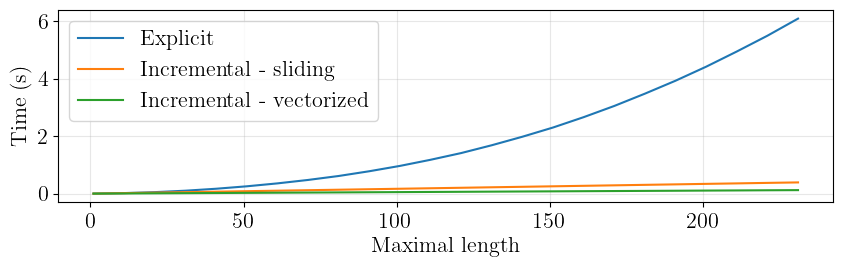

In [2]:
df = pd.read_csv("results/sum_metrics.csv")
lengths = np.arange(1, 241, 10)
plt.figure(figsize=(10,2.5))
plt.plot(lengths, df['explicit'], label='Explicit')
plt.plot(lengths, df['sliding'], label='Incremental - sliding')
plt.plot(lengths, df['vectorized'], label='Incremental - vectorized')
plt.legend()
plt.xlabel('Maximal length')
plt.ylabel('Time (s)')
plt.grid(True, alpha=0.3)  
plt.savefig("figures/sum_compute.pdf", format="pdf", bbox_inches='tight')
plt.show()

# Period length scaling

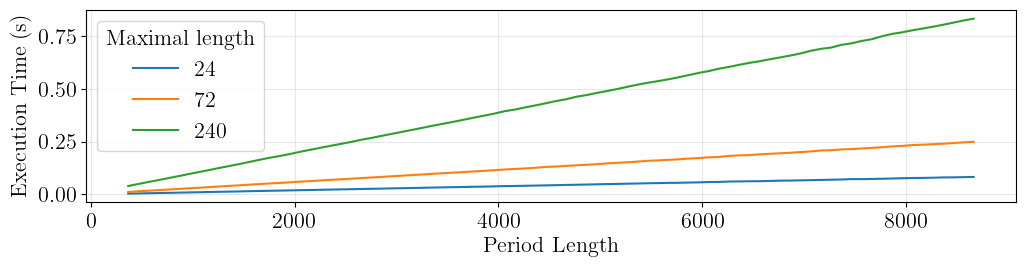

In [3]:
df = pd.read_csv("results/scaling_metrics.csv")
max_lengths = df['max_length'].unique()
plt.figure(figsize=(12, 2.5))
for max_length in max_lengths:
    mask = (df['experiment'] == 'period_length_scaling') & (
        df['max_length'] == max_length)
    plt.plot(df[mask]['period_length'], df[mask]['time_mean'],
             label=f'{max_length}')
plt.xlabel('Period Length')
plt.ylabel('Execution Time (s)')
plt.legend(title="Maximal length")
plt.grid(True, alpha=0.3)  
plt.savefig("figures/period_length_scaling_results.pdf", format="pdf", bbox_inches='tight')
plt.show()

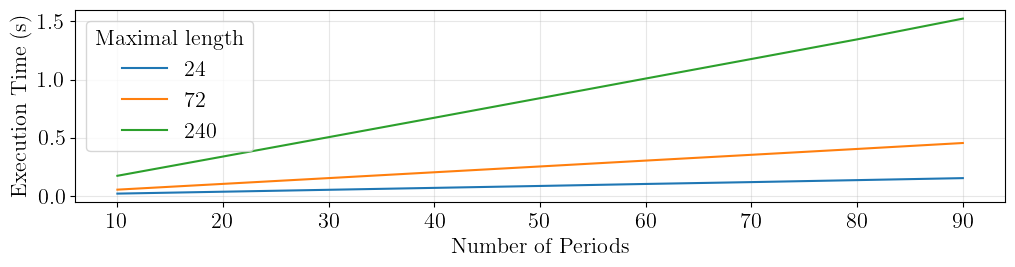

In [4]:
 plt.figure(figsize=(12, 2.5))
for max_length in max_lengths:
    mask = (df['experiment'] == 'n_period_scaling') & (
        df['max_length'] == max_length)
    plt.plot(df[mask]['n_period'], df[mask]['time_mean'],
             label=f'{max_length}')
plt.xlabel('Number of Periods')
plt.ylabel('Execution Time (s)')
plt.legend(title="Maximal length")
plt.grid(True, alpha=0.3)  
plt.savefig("figures/n_period_scaling_results.pdf", format="pdf", bbox_inches='tight')
plt.show()

# Skipping tradeoff

## Date skipping tradeoff

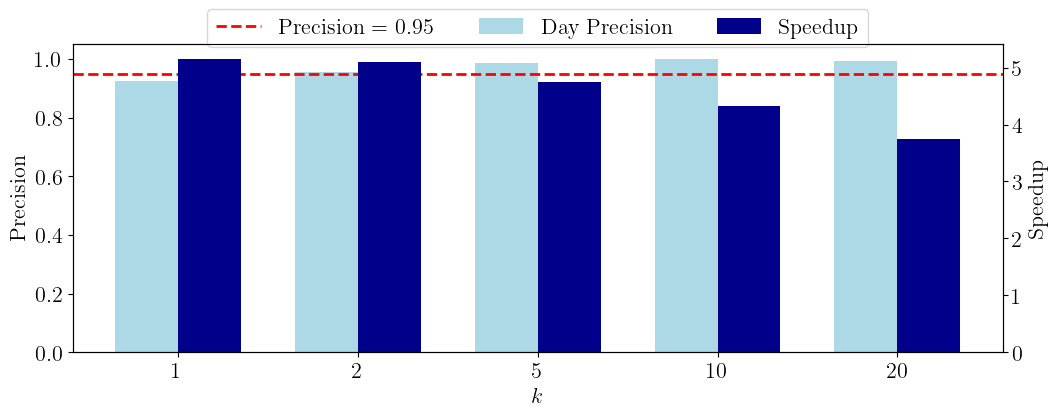

In [15]:
date_results = pd.read_csv("results/date_skipping_results.csv")

fig1, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()

x = np.arange(len(date_results['skip_factor']))
width = 0.35

rects1 = ax1.bar(x - width/2, date_results['day_precision'], width, label='Day Precision', color='lightblue')
rects2 = ax2.bar(x + width/2, date_results['speedup'], width, label='Speedup', color='darkblue')

ax1.set_xlabel('$k$')
ax1.set_ylabel('Precision')
ax2.set_ylabel('Speedup')
ax1.set_xticks(x)
ax1.set_xticklabels(date_results['skip_factor'])

ax1.axhline(y=0.95, color='red', linestyle='--', linewidth=2, label='Precision = 0.95', zorder=3)

# Add legends for both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=3)
plt.savefig("figures/date_tradeoff_results.pdf", format="pdf", bbox_inches='tight')

## Length skipping tradeoff

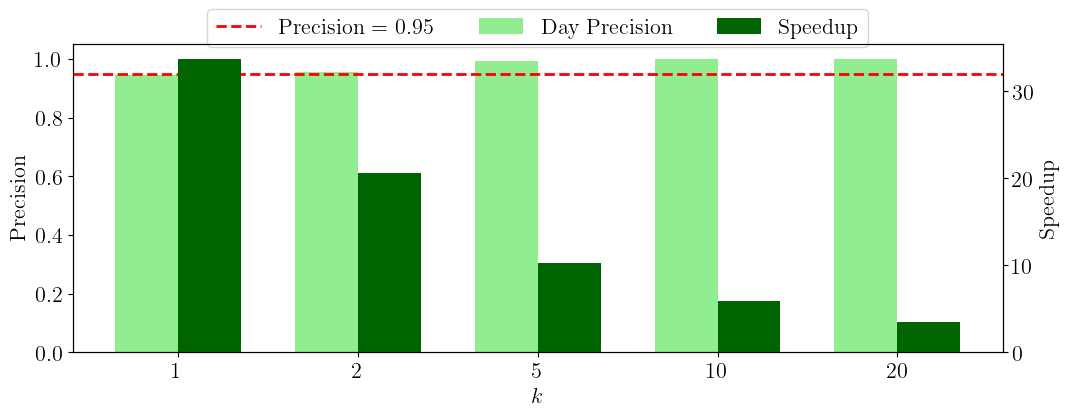

In [14]:
length_results = pd.read_csv("results/length_skipping_results.csv")

fig2, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()

rects1 = ax1.bar(x - width/2, length_results['day_precision'], width, label='Day Precision', color='lightgreen')
rects2 = ax2.bar(x + width/2, length_results['speedup'], width, label='Speedup', color='darkgreen')

ax1.set_xlabel('$k$')
ax1.set_ylabel('Precision')
ax2.set_ylabel('Speedup')
ax1.set_xticks(x)
ax1.set_xticklabels(length_results['skip_factor'])
ax1.axhline(y=0.95, color='red', linestyle='--', linewidth=2, label='Precision = 0.95', zorder=3)

# Add legends for both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=3)
plt.savefig("figures/length_tradeoff_results.pdf", format="pdf", bbox_inches='tight')

## Grid skipping tradeoff

### Mediterranean SST

In [8]:
results_df = pd.read_csv("results/grid_tradeoff_metrics.csv")
skip_factors = pd.to_numeric(results_df['skip_factor'], errors='coerce').dropna().astype(int).unique()

info_per_skip_factor = {}
for skip_factor, group in results_df.groupby('skip_factor'):
    total_baseline_days = pd.to_numeric(group['baseline_days'], errors='coerce').fillna(0).sum()
    total_baseline_time = pd.to_numeric(group['baseline_time'], errors='coerce').fillna(0).sum()
    total_execution_time = pd.to_numeric(group['execution_time'], errors='coerce').fillna(0).sum()
    detected_days = pd.to_numeric(group['detected_days'], errors='coerce').fillna(0).sum()

    if total_execution_time > 0 and total_baseline_days > 0:  # Avoid division by zero
        speedup = total_baseline_time / total_execution_time
        day_precision = detected_days / total_baseline_days
    else:
        speedup, day_precision = 0, 0  # Handle division errors gracefully

    info_per_skip_factor[skip_factor] = {
        "speedup": np.round(speedup,1),
        "day_precision": np.round(day_precision,3)*100
    }
info_df = pd.DataFrame.from_dict(info_per_skip_factor, orient='index')

# Format the table nicely
info_df.index.name = "Skip Factor"
info_df.reset_index(inplace=True)

# Display the table
from tabulate import tabulate
print(tabulate(info_df, headers='keys', tablefmt='pretty'))

+---+-------------+---------+---------------+
|   | Skip Factor | speedup | day_precision |
+---+-------------+---------+---------------+
| 0 |     1.0     |  37.3   |     79.0      |
| 1 |     2.0     |  22.9   |     88.5      |
| 2 |     5.0     |  11.5   |     93.4      |
| 3 |    10.0     |   6.6   |     97.3      |
| 4 |    20.0     |   3.9   |     98.7      |
+---+-------------+---------+---------------+


### Europe 2m temperature

In [9]:
results_df = pd.read_csv("results/grid_tradeoff_metrics_t2m.csv")
skip_factors = pd.to_numeric(results_df['skip_factor'], errors='coerce').dropna().astype(int).unique()

info_per_skip_factor = {}
for skip_factor, group in results_df.groupby('skip_factor'):
    total_baseline_days = pd.to_numeric(group['baseline_days'], errors='coerce').fillna(0).sum()
    total_baseline_time = pd.to_numeric(group['baseline_time'], errors='coerce').fillna(0).sum()
    total_execution_time = pd.to_numeric(group['execution_time'], errors='coerce').fillna(0).sum()
    detected_days = pd.to_numeric(group['detected_days'], errors='coerce').fillna(0).sum()

    if total_execution_time > 0 and total_baseline_days > 0:  # Avoid division by zero
        speedup = total_baseline_time / total_execution_time
        day_precision = detected_days / total_baseline_days
    else:
        speedup, day_precision = 0, 0  # Handle division errors gracefully

    info_per_skip_factor[skip_factor] = {
        "speedup": np.round(speedup,1),
        "day_precision": np.round(day_precision*100,1)
    }
info_df = pd.DataFrame.from_dict(info_per_skip_factor, orient='index')

# Format the table nicely
info_df.index.name = "Skip Factor"
info_df.reset_index(inplace=True)

# Display the table
from tabulate import tabulate
print(tabulate(info_df, headers='keys', tablefmt='pretty'))

+---+-------------+---------+---------------+
|   | Skip Factor | speedup | day_precision |
+---+-------------+---------+---------------+
| 0 |     1.0     |  37.9   |     69.2      |
| 1 |     2.0     |  23.5   |     79.4      |
| 2 |     5.0     |  11.8   |     88.4      |
| 3 |    10.0     |   6.9   |     95.2      |
| 4 |    20.0     |   4.0   |     97.9      |
+---+-------------+---------+---------------+


### Europe Total Precipitation

In [10]:
results_df = pd.read_csv("results/grid_tradeoff_metrics_tp.csv")
skip_factors = pd.to_numeric(results_df['skip_factor'], errors='coerce').dropna().astype(int).unique()

info_per_skip_factor = {}
for skip_factor, group in results_df.groupby('skip_factor'):
    total_baseline_days = pd.to_numeric(group['baseline_days'], errors='coerce').fillna(0).sum()
    total_baseline_time = pd.to_numeric(group['baseline_time'], errors='coerce').fillna(0).sum()
    total_execution_time = pd.to_numeric(group['execution_time'], errors='coerce').fillna(0).sum()
    detected_days = pd.to_numeric(group['detected_days'], errors='coerce').fillna(0).sum()

    if total_execution_time > 0 and total_baseline_days > 0:  # Avoid division by zero
        speedup = total_baseline_time / total_execution_time
        day_precision = detected_days / total_baseline_days
    else:
        speedup, day_precision = 0, 0  # Handle division errors gracefully

    info_per_skip_factor[skip_factor] = {
        "speedup": np.round(speedup,1),
        "day_precision": np.round(day_precision*100,1)
    }
info_df = pd.DataFrame.from_dict(info_per_skip_factor, orient='index')

# Format the table nicely
info_df.index.name = "Skip Factor"
info_df.reset_index(inplace=True)

# Display the table
from tabulate import tabulate
print(tabulate(info_df, headers='keys', tablefmt='pretty'))


+---+-------------+---------+---------------+
|   | Skip Factor | speedup | day_precision |
+---+-------------+---------+---------------+
| 0 |     1.0     |  62.1   |     63.3      |
| 1 |     2.0     |  36.4   |     75.7      |
| 2 |     5.0     |  17.6   |     86.8      |
| 3 |    10.0     |   8.7   |     93.4      |
| 4 |    20.0     |   4.5   |     97.2      |
+---+-------------+---------+---------------+


## Online Processing Time

<>:7: SyntaxWarning: invalid escape sequence '\('
<>:7: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_177028/4031828520.py:7: SyntaxWarning: invalid escape sequence '\('
  plt.ylabel('Execution Time (\(\mu\)s)')


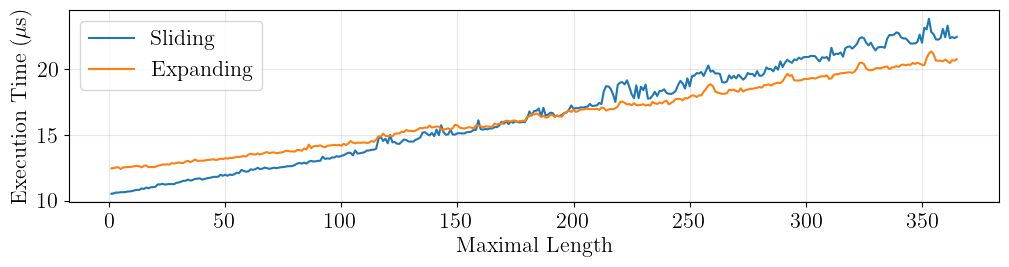

In [22]:
df = pd.read_csv("results/online_scaling_metrics.csv")

plt.figure(figsize=(12, 2.5))
plt.plot(df['max_length'], df['processing_time_sliding'], label='Sliding')
plt.plot(df['max_length'], df['processing_time_expanding'], label='Expanding')
plt.xlabel('Maximal Length')
plt.ylabel('Execution Time (\(\mu\)s)') 
plt.legend()
plt.grid(True, alpha=0.3)  
plt.savefig("figures/processing_time.pdf", format="pdf", bbox_inches='tight')

# Numerical Precision

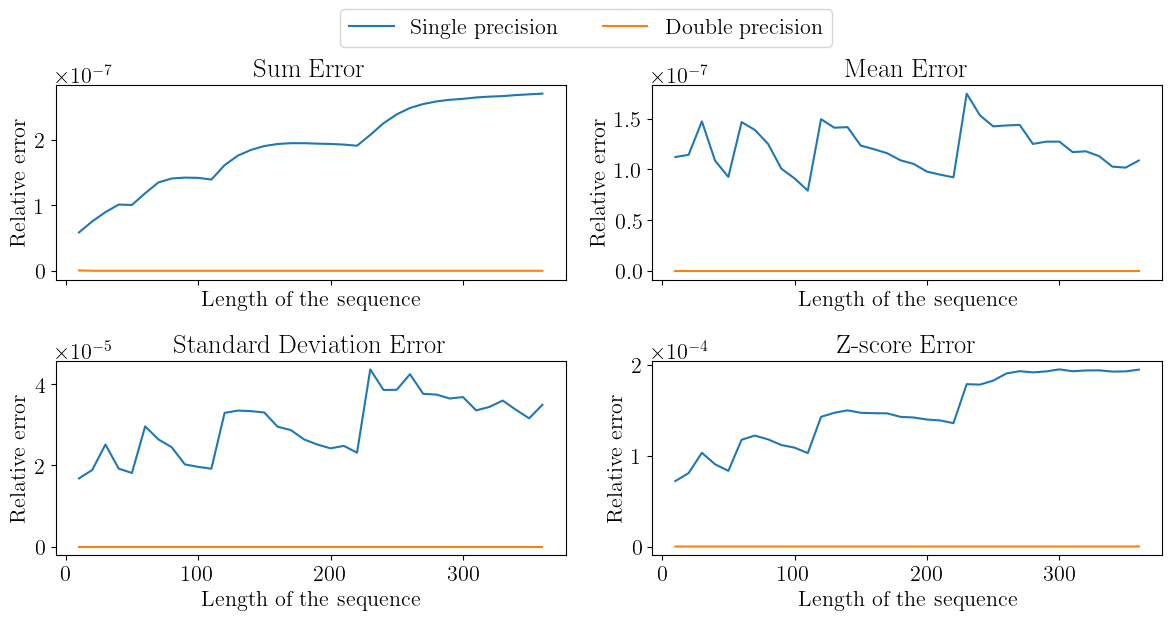

In [7]:
df = pd.read_csv("results/numerical_metrics.csv")

fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
max_length = np.max(df['lengths'])
min_length = np.min(df['lengths'])
step = (max_length-min_length)//len(df['lengths']) + 1

axs[0,0].plot(range(step, max_length+1, step), df['sums_error_single'], label='Single precision')
axs[0,0].plot(range(step, max_length+1, step), df['sums_error_double'], label='Double precision')
axs[0,0].set_xlabel('Length of the sequence')
axs[0,0].set_ylabel('Relative error')
axs[0,0].set_title('Sum Error')

axs[0,1].plot(range(step, max_length+1, step), df['mean_error_single'])
axs[0,1].plot(range(step, max_length+1, step), df['mean_error_double'])
axs[0,1].set_xlabel('Length of the sequence')
axs[0,1].set_ylabel('Relative error')
axs[0,1].set_title('Mean Error')

axs[1,0].plot(range(step, max_length+1, step), df['std_error_single'])
axs[1,0].plot(range(step, max_length+1, step), df['std_error_double'])
axs[1,0].set_xlabel('Length of the sequence')
axs[1,0].set_ylabel('Relative error')
axs[1,0].set_title('Standard Deviation Error')

axs[1,1].plot(range(step, max_length+1, step), df['z-score_error_single'])
axs[1,1].plot(range(step, max_length+1, step), df['z-score_error_double'])
axs[1,1].set_xlabel('Length of the sequence')
axs[1,1].set_ylabel('Relative error')
axs[1,1].set_title('Z-score Error')
axs[1,1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))

lines, labels = [], []
for row in axs:
    for ax in row:
        ax_lines, ax_labels = ax.get_legend_handles_labels()
        lines.extend(ax_lines)
        labels.extend(ax_labels)
plt.tight_layout()
fig.legend(lines, labels, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.06))
plt.savefig("figures/numerical_precision.pdf", format="pdf", bbox_inches='tight')